In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Load the Titanic dataset
df = sns.load_dataset("titanic")

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())

Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names and data types
df.info()

# Check missing values in each column
print("\nMissing values:")
print(df.isna().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB

Missing values:
survived         0
pclass           0
sex           

In [3]:
# Fill missing age values using the median of the same class and sex
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill missing embarked values with the most common port
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

# Drop deck because it contains many missing values
df = df.drop(columns=["deck"])

# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isna().sum())

Missing values after cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


In [4]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check data types after cleaning
df.info()

Duplicate rows: 118
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          891 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     891 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  embark_town  889 non-null    str     
 12  alive        891 non-null    str     
 13  alone        891 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(4), str(5)
memory usage: 79.4 KB


In [5]:
# Calculate survival rate by sex
survival_by_sex = df.groupby("sex")["survived"].mean()

print("Survival rate by sex:")
print((survival_by_sex * 100).round(2))

Survival rate by sex:
sex
female    74.20
male      18.89
Name: survived, dtype: float64


In [6]:
# Calculate survival rate and passenger count by class
survival_by_class = df.groupby("pclass")["survived"].agg(
    ["mean", "count"]
)

survival_by_class["mean"] = survival_by_class["mean"] * 100

survival_by_class = survival_by_class.rename(
    columns={"mean": "Survival Rate (%)", "count": "Passenger Count"}
)

print("Survival rate by passenger class:")
display(survival_by_class.round(2))

Survival rate by passenger class:


,Survival Rate (%),Passenger Count
pclass,,
1,62.96,216
2,47.28,184
3,24.24,491


In [7]:
# Create age groups
df["age_band"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 40, 60, 100],
    labels=["Child", "Teen", "Adult", "Middle-aged", "Senior"]
)

# Calculate survival rate by age group
survival_by_age = df.groupby("age_band", observed=True)["survived"].mean() * 100

print("Survival rate by age group:")
display(survival_by_age.round(2))

Survival rate by age group:


age_band
Child          57.97
Teen           42.86
Adult          36.05
Middle-aged    39.06
Senior         22.73
Name: survived, dtype: float64

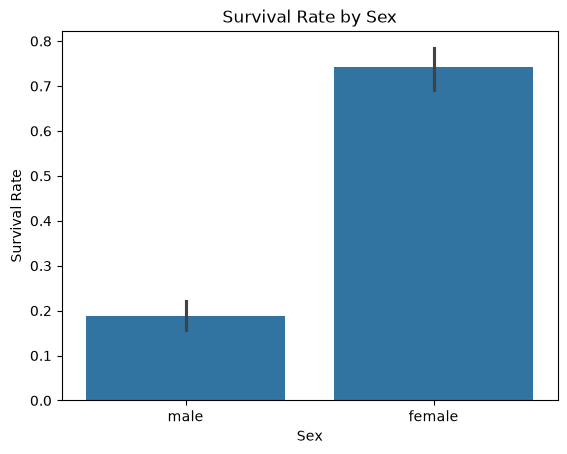

In [8]:
sns.barplot(data=df, x="sex", y="survived")

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.show()

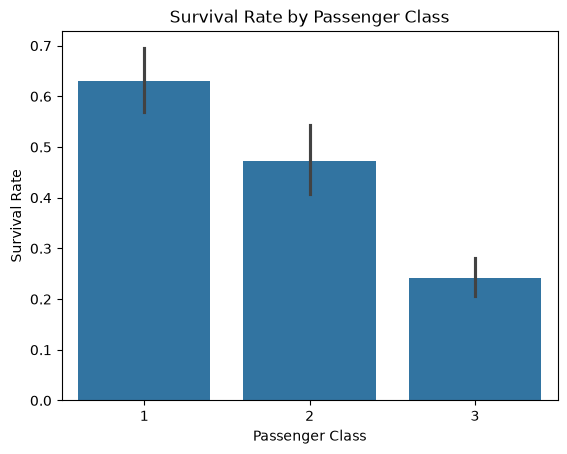

In [9]:
sns.barplot(data=df, x="pclass", y="survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

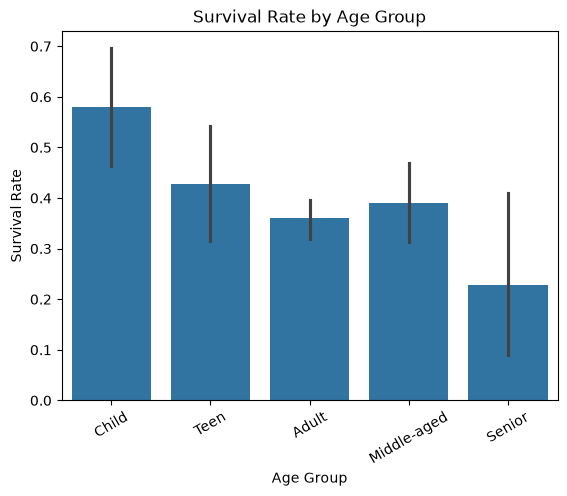

In [10]:
sns.barplot(data=df, x="age_band", y="survived")

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.xticks(rotation=30)
plt.show()

## Key Findings

1. **Survival by sex:** Female passengers had a survival rate of **74.20%**, compared with **18.89%** for male passengers. This indicates a substantial difference in survival rates between the sexes.

2. **Survival by passenger class:** First-class passengers had a survival rate of **62.96%**, second-class passengers had **47.28%**, and third-class passengers had **24.24%**. Passengers in higher classes had higher survival rates in this dataset.

3. **Survival by age group:** Children had the highest survival rate at **57.97%**, while seniors had the lowest at **22.73%**. Teenagers had a survival rate of **42.86%**, adults **36.05%**, and middle-aged passengers **39.06%**.



In [11]:
print("Survival by sex (%)")
print((df.groupby("sex")["survived"].mean() * 100).round(2))

print("\nSurvival by passenger class (%)")
print((df.groupby("pclass")["survived"].mean() * 100).round(2))

print("\nSurvival by age group (%)")
print((df.groupby("age_band", observed=True)["survived"].mean() * 100).round(2))

Survival by sex (%)
sex
female    74.20
male      18.89
Name: survived, dtype: float64

Survival by passenger class (%)
pclass
1    62.96
2    47.28
3    24.24
Name: survived, dtype: float64

Survival by age group (%)
age_band
Child          57.97
Teen           42.86
Adult          36.05
Middle-aged    39.06
Senior         22.73
Name: survived, dtype: float64
